In [1]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
import os
import numpy as np
import pandas as pd

In [4]:
file_path = '/content/drive/MyDrive/datasets/iris_data.csv'
data = pd.read_csv(file_path)
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
# Number of data points(rows)
len(data)

150

In [6]:
data.shape[0]

150

In [7]:
# Column Names
data.columns.to_list()

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

In [8]:
# Data types for each column
data.dtypes

,0
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,object


In [9]:
# number of each specis precent.
data.species.value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


In [10]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
stats_df = data.describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']
stats_df

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000
range,3.600000,2.400000,5.900000,2.400000


In [12]:
out_fields = ['mean', '25%', '50%', '75%', "range"]
stats_df = stats_df.loc[out_fields]
stats_df

,sepal_length,sepal_width,petal_length,petal_width
mean,5.843333,3.054,3.758667,1.198667
25%,5.100000,2.800,1.600000,0.300000
50%,5.800000,3.000,4.350000,1.300000
75%,6.400000,3.300,5.100000,1.800000
range,3.600000,2.400,5.900000,2.400000


In [13]:
stats_df.rename({'50%': 'median'}, inplace=True)
stats_df

,sepal_length,sepal_width,petal_length,petal_width
mean,5.843333,3.054,3.758667,1.198667
25%,5.100000,2.800,1.600000,0.300000
median,5.800000,3.000,4.350000,1.300000
75%,6.400000,3.300,5.100000,1.800000
range,3.600000,2.400,5.900000,2.400000


In [14]:
# Mean of each measurement (sepal_length, sepal_width, petal_length, petal_width)
data.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [15]:
# median of each of these measurements
data.groupby('species').median()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.0,3.4,1.50,0.2
versicolor,5.9,2.8,4.35,1.3
virginica,6.5,3.0,5.55,2.0


In [16]:
# Apply multiple functions at onece - 2 methods
data.groupby('species').agg(['mean', 'median']) # passing a list of recognized strings

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

In [17]:
data.groupby('species').agg([np.mean, np.median]) # passing a list of explict aggregation functions

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

In [18]:
agg_dict = {field: ['mean', 'median'] for field in data.columns if field != 'species'}
agg_dict

{'sepal_length': ['mean', 'median'],
 'sepal_width': ['mean', 'median'],
 'petal_length': ['mean', 'median'],
 'petal_width': ['mean', 'median']}

In [19]:
# if certain fields need to be aggregated differently, we can do:
from pprint import pprint

agg_dict = {field: ['mean', 'median'] for field in data.columns if field != 'species'}
agg_dict['petal_length'] = 'max'
pprint(agg_dict)

{'petal_length': 'max',
 'petal_width': ['mean', 'median'],
 'sepal_length': ['mean', 'median'],
 'sepal_width': ['mean', 'median']}


In [31]:
data.groupby('species').agg(agg_dict)

sepal_length        sepal_width        petal_length petal_width  \
                   mean median        mean median          max        mean   
species                                                                      
setosa            5.006    5.0       3.418    3.4          1.9       0.244   
versicolor        5.936    5.9       2.770    2.8          5.1       1.326   
virginica         6.588    6.5       2.974    3.0          6.9       2.026   

                   
           median  
species            
setosa        0.2  
versicolor    1.3  
virginica     2.0

In [20]:
# make a scatter plot of sepal_length vs spal_widh using Matplotlib

import matplotlib.pyplot as plt
%matplotlib inline

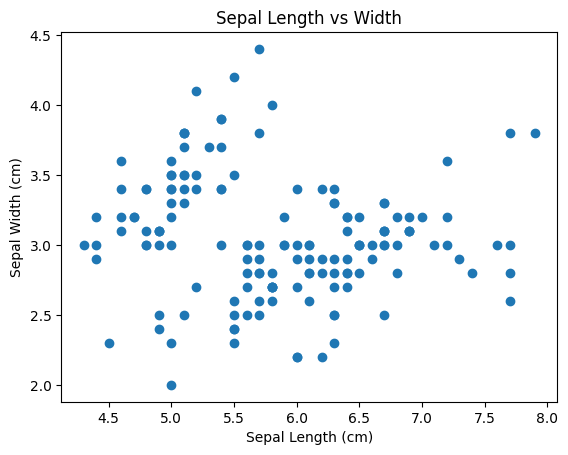

In [21]:
# A simple scatter plot with Matplotlib
ax = plt.axes()

ax.scatter(data.sepal_length, data.sepal_width)

# Label
ax.set(xlabel='Sepal Length (cm)', ylabel='Sepal Width (cm)', title='Sepal Length vs Width');

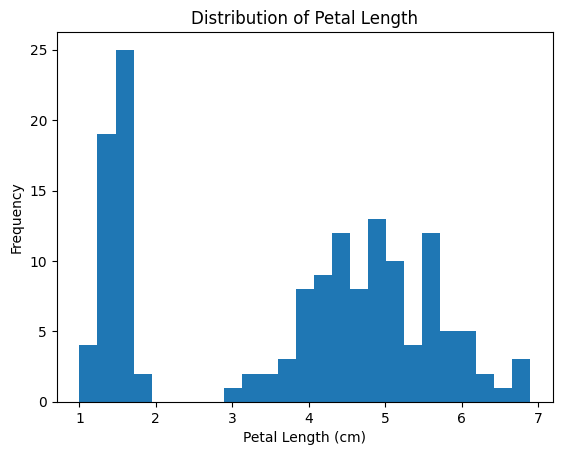

In [22]:
# Make a histrogram of any one of the four fetures

ax = plt.axes()
ax.hist(data.petal_length, bins=25);

ax.set(xlabel='Petal Length (cm)', ylabel='Frequency', title='Distribution of Petal Length');

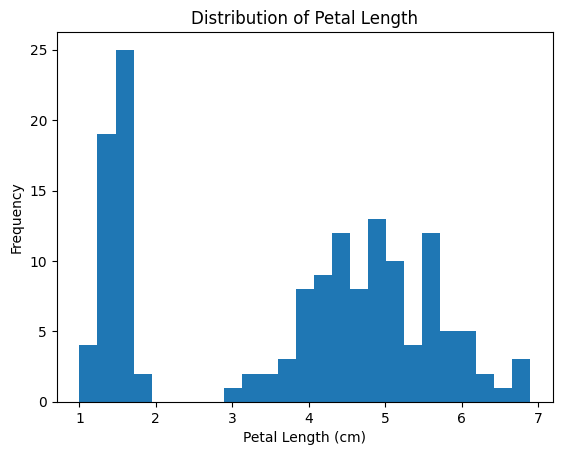

In [35]:
# Alternatively using Pands plotting functionality
ax = data.petal_length.plot.hist(bins=25)
ax.set(xlabel='Petal Length (cm)', ylabel='Frequency', title='Distribution of Petal Length');

Text(0.5, 0, 'Size (cm)')

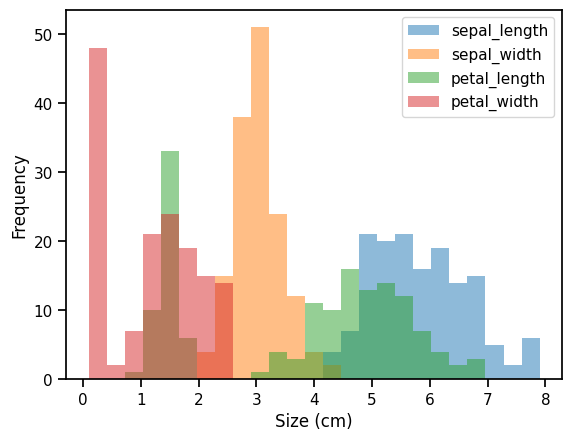

In [17]:
# Create a Single plot with histrograms for each features (petal_width, Petal_length, sepal_length)
import seaborn as sns
sns.set_context('notebook')

ax = data.plot.hist(bins=25, alpha=0.5)
ax.set_xlabel('Size (cm)')

In [42]:
axList.flatten()

array([<Axes: title={'center': 'sepal_length'}>,
       <Axes: title={'center': 'sepal_width'}>,
       <Axes: title={'center': 'petal_length'}>,
       <Axes: title={'center': 'petal_width'}>], dtype=object)

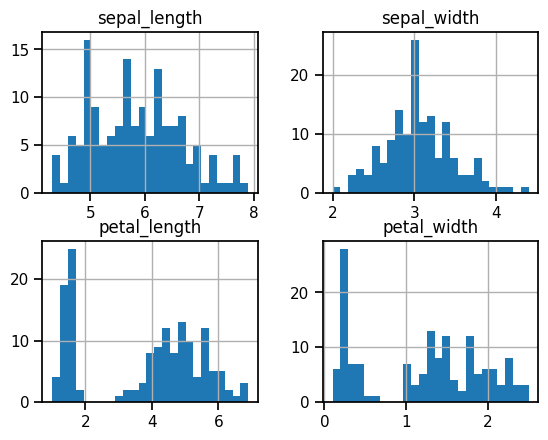

In [ ]:
# to create for separate plots, use Pandas and last row

axList = data.hist(bins=25)

array([[<Axes: title={'center': 'petal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'petal_width'}, xlabel='[species]'>],
       [<Axes: title={'center': 'sepal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'sepal_width'}, xlabel='[species]'>]],
      dtype=object)

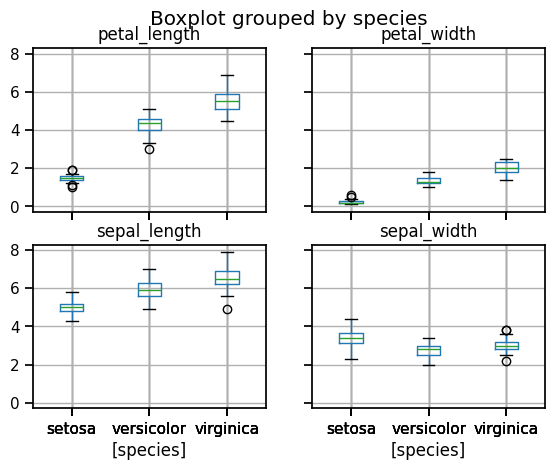

In [43]:
# Box plot
data.boxplot(by='species')

In [8]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [12]:
data.set_index('species')

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.1,3.5,1.4,0.2
setosa,4.9,3.0,1.4,0.2
setosa,4.7,3.2,1.3,0.2
setosa,4.6,3.1,1.5,0.2
setosa,5.0,3.6,1.4,0.2
...,...,...,...,...
virginica,6.7,3.0,5.2,2.3
virginica,6.3,2.5,5.0,1.9
virginica,6.5,3.0,5.2,2.0


In [11]:
data.set_index('species').stack()

species                
setosa     sepal_length    5.1
           sepal_width     3.5
           petal_length    1.4
           petal_width     0.2
           sepal_length    4.9
                          ... 
virginica  petal_width     2.3
           sepal_length    5.9
           sepal_width     3.0
           petal_length    5.1
           petal_width     1.8
Length: 600, dtype: float64

In [14]:
data.set_index('species').stack().to_frame().reset_index()

,species,level_1,0
0,setosa,sepal_length,5.1
1,setosa,sepal_width,3.5
2,setosa,petal_length,1.4
3,setosa,petal_width,0.2
4,setosa,sepal_length,4.9
...,...,...,...
595,virginica,petal_width,2.3
596,virginica,sepal_length,5.9
597,virginica,sepal_width,3.0
598,virginica,petal_length,5.1


In [15]:
data.set_index('species').stack().to_frame().reset_index().rename(columns={0:'size', 'level_1': 'measurement'})

,species,measurement,size
0,setosa,sepal_length,5.1
1,setosa,sepal_width,3.5
2,setosa,petal_length,1.4
3,setosa,petal_width,0.2
4,setosa,sepal_length,4.9
...,...,...,...
595,virginica,petal_width,2.3
596,virginica,sepal_length,5.9
597,virginica,sepal_width,3.0
598,virginica,petal_length,5.1


In [16]:
# Single boxplot where the features are separated in the x-axis and species are colored with diffrent hues.

plot_data = (data.set_index('species').stack().to_frame().reset_index().rename(columns={0:'size', 'level_1': 'measurement'}))

plot_data.head()

,species,measurement,size
0,setosa,sepal_length,5.1
1,setosa,sepal_width,3.5
2,setosa,petal_length,1.4
3,setosa,petal_width,0.2
4,setosa,sepal_length,4.9


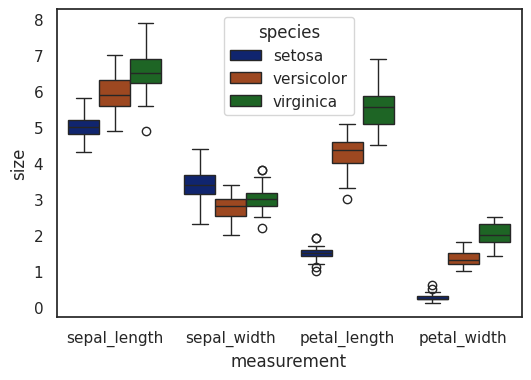

In [20]:
import seaborn as sns

import matplotlib.pyplot as plt
%matplotlib inline

# Now Plot the dataframe from above using Seaborn
sns.set_style('white')
sns.set_context('notebook')
sns.set_palette('dark')

f = plt.figure(figsize=(6,4))
sns.boxplot(x='measurement', y='size', hue='species', data=plot_data);


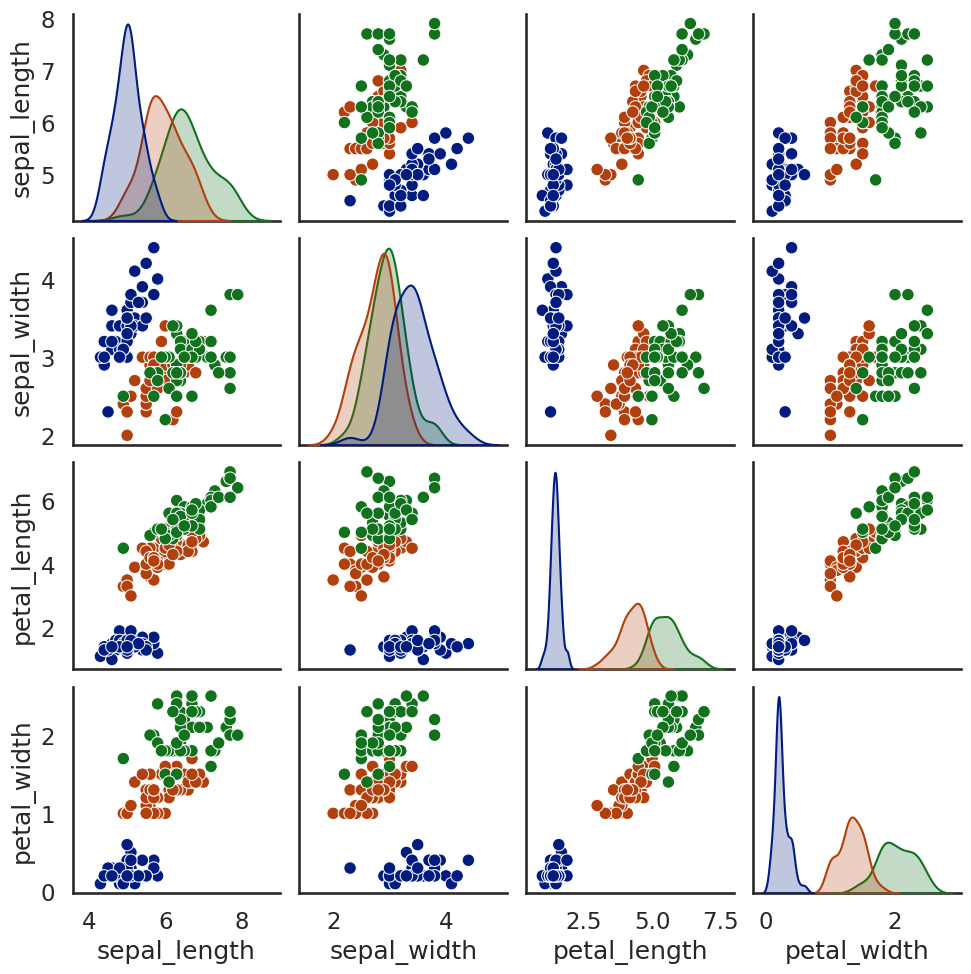

In [22]:
# Make a pairplot with Seaborn to examine the correlation between wach of the measurements.

sns.set_context('talk')
plot = sns.pairplot(data, hue='species')
plot._legend.remove()
plot

------------------------------------------

| <img src="https://github.com/madhawapolkotuwa.png" width="80" style="border-radius: 50%;"> | **MPCoding**<br>*Machine Learning Tutorial Series*<br><br> [![YouTube](https://img.shields.io/badge/YouTube-%23FF0000.svg?style=for-the-badge&logo=YouTube&logoColor=white)](https://www.youtube.com/@MP-Coding) [![GitHub](https://img.shields.io/badge/github-repo-blue?logo=github)](https://github.com/madhawapolkotuwa) |
|---|---|

<p align="left" style="font-size: 0.85em; color: gray; margin-top: 10px;">
  © 2026 MPCoding. Educational materials are free to use with proper attribution.
</p>